# Outlier Analysis

## 1. Introduction

Outlier analysis is the process of identifying data points that are very different from other observations in a dataset.

Outliers may occur due to measurement errors, data entry mistakes, or genuine unusual observations.

### Objectives
- Understand outliers and their effects.
- Detect outliers using the IQR method.
- Visualize outliers using box plots.
- Identify possible outliers in numerical features.
- Understand the importance of outlier analysis in machine learning.

## 2. Understanding Outliers

An outlier is a value that differs significantly from most other values in a dataset.

For example, if most students score between 40 and 90 marks, a score of 150 may be an unusual value that needs investigation.

Outliers can affect statistical measures such as the mean, standard deviation, and correlation.

**AI/ML relevance:** Outlier analysis helps improve data quality and helps us decide whether unusual observations need correction, retention, or further investigation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


## 3. Loading the Dataset

I will load the `ml_training_data.csv` dataset using Pandas. I will use the numerical features to identify and analyze possible outliers.

In [2]:
df = pd.read_csv("ml_training_data.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (5, 3)


,Study_Hours,Attendance,Exam_Marks
0,2,60,50
1,3,65,55
2,4,75,65
3,5,85,75
4,6,95,90


## 4. Selecting Numerical Features

Outlier detection methods such as IQR are commonly applied to numerical features. I will select the numerical columns from the dataset for analysis.

In [3]:
numerical_df = df.select_dtypes(include="number")

print("Numerical columns:")
print(numerical_df.columns.tolist())

display(numerical_df.describe())

Numerical columns:
['Study_Hours', 'Attendance', 'Exam_Marks']


,Study_Hours,Attendance,Exam_Marks
count,5.000000,5.000000,5.000000
mean,4.000000,76.000000,67.000000
std,1.581139,14.317821,16.046807
min,2.000000,60.000000,50.000000
25%,3.000000,65.000000,55.000000
50%,4.000000,75.000000,65.000000
75%,5.000000,85.000000,75.000000
max,6.000000,95.000000,90.000000


## 5. Outlier Detection Using the IQR Method

The Interquartile Range (IQR) measures the spread of the middle 50% of the data.

- Q1 is the 25th percentile.
- Q3 is the 75th percentile.
- IQR = Q3 - Q1.
- Lower bound = Q1 - 1.5 × IQR.
- Upper bound = Q3 + 1.5 × IQR.

Values below the lower bound or above the upper bound are flagged as potential outliers.

In [4]:
Q1 = numerical_df.quantile(0.25)
Q3 = numerical_df.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (numerical_df < lower_bound) |
    (numerical_df > upper_bound)
)

print("Lower bounds:")
display(lower_bound)

print("Upper bounds:")
display(upper_bound)

print("Potential outliers in each numerical column:")
display(outlier_mask.sum().to_frame(name="Outlier Count"))

Lower bounds:


Study_Hours     0.0
Attendance     35.0
Exam_Marks     25.0
dtype: float64

Upper bounds:


Study_Hours      8.0
Attendance     115.0
Exam_Marks     105.0
dtype: float64

Potential outliers in each numerical column:


,Outlier Count
Study_Hours,0
Attendance,0
Exam_Marks,0


## 6. Identifying Potential Outlier Records

I will display the rows that contain at least one potential outlier according to the IQR method. These records should be investigated before deciding whether any changes are necessary.

In [5]:
outlier_rows = df.loc[outlier_mask.any(axis=1)]

print("Number of rows with at least one potential outlier:", len(outlier_rows))
display(outlier_rows.head(10))

Number of rows with at least one potential outlier: 0


,Study_Hours,Attendance,Exam_Marks


## 7. Visualizing Outliers Using Box Plots

A box plot shows the median, quartiles, and possible outliers in a numerical feature. Points beyond the whiskers may be potential outliers according to the box plot's rule.

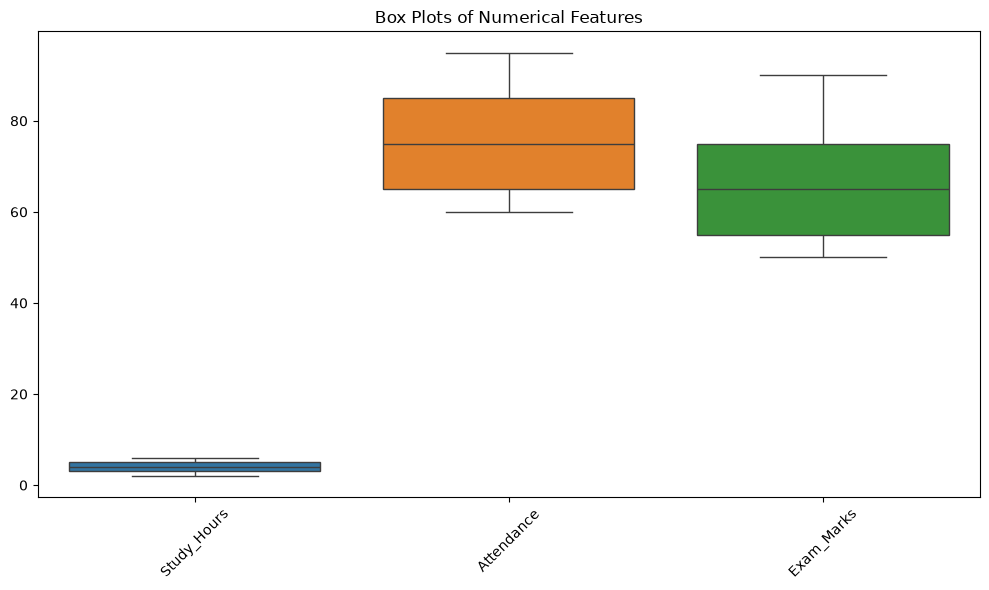

In [6]:
if numerical_df.shape[1] > 0:
    plt.figure(figsize=(10, 6))
    sns.boxplot(data=numerical_df)
    plt.title("Box Plots of Numerical Features")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No numerical columns are available.")

## 8. Individual Feature Analysis

I will examine each numerical feature separately to understand its distribution and identify possible unusual values.

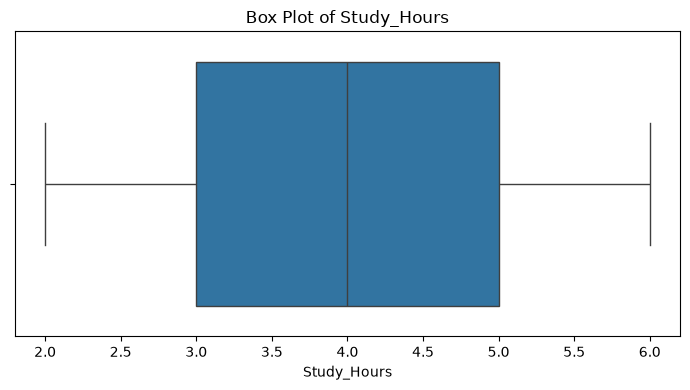

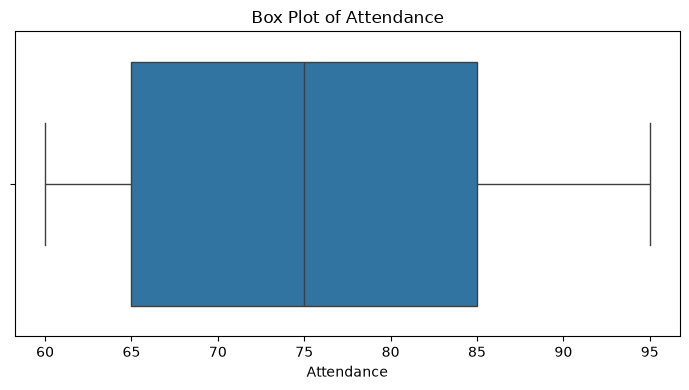

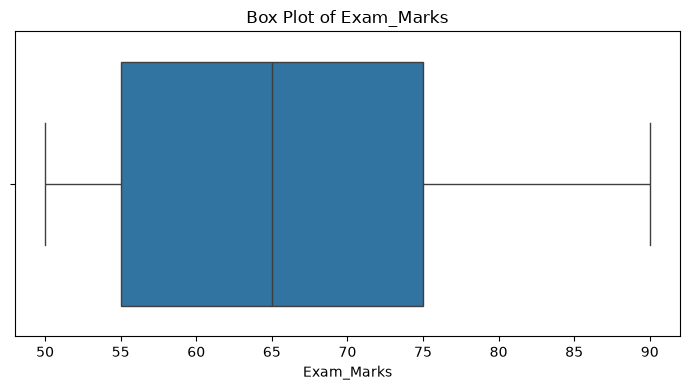

In [7]:
for column in numerical_df.columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=numerical_df[column])
    plt.title(f"Box Plot of {column}")
    plt.tight_layout()
    plt.show()

## 9. Effect of Outliers on Statistical Measures

Outliers can affect the mean and standard deviation more strongly than the median. Comparing these measures helps us understand whether unusual values may influence the summary of a feature.

However, an outlier is not always an error and should not be removed without investigation.

In [8]:
summary = pd.DataFrame({
    "Mean": numerical_df.mean(),
    "Median": numerical_df.median(),
    "Standard Deviation": numerical_df.std(),
    "Minimum": numerical_df.min(),
    "Maximum": numerical_df.max()
})

display(summary.round(2))

,Mean,Median,Standard Deviation,Minimum,Maximum
Study_Hours,4.0,4.0,1.58,2,6
Attendance,76.0,75.0,14.32,60,95
Exam_Marks,67.0,65.0,16.05,50,90


## 10. Observations and Insights

1. The IQR method identifies potential outliers using the lower and upper bounds.
2. The outlier count shows how many values are flagged in each numerical feature.
3. Box plots help visualize the spread of values and possible outliers.
4. Comparing the mean and median helps us understand how unusual values may affect summary statistics.
5. Potential outliers should be investigated to determine whether they are errors or valid observations.
6. Outliers should not be removed automatically because they may contain useful information.

**Note:** Update these observations based on the actual outlier counts, bounds, and box plots produced by the notebook.

## 11. AI/ML Relevance

Outlier analysis is an important part of data preprocessing in machine learning.

Outliers may affect algorithms that are sensitive to extreme values, such as linear regression and K-nearest neighbors. Tree-based models may be less sensitive to some outliers.

Depending on the data and the problem, potential outliers may be retained, corrected, transformed, or treated using suitable methods.

## 12. Conclusion

In this notebook, I performed outlier analysis using the IQR method, outlier counts, and box plots. I also compared statistical measures to understand the possible effects of unusual values.

I learned that potential outliers should be investigated carefully before making changes to a dataset. This process helps prepare cleaner and more reliable data for machine learning.